# ProtoStar — data engineering

This notebook builds an auditable city-year climate table from the official historical dataset. It deliberately stops before model fitting: all transformations here should be safe to reuse in chronological forecasting backtests.

**Workflow:** load official yearly data → inspect schema → validate records and coverage → create model-ready city-year data → save reproducible outputs.

## Setup

Run this cell once in a fresh environment. The project uses Python 3.13+; if a package is unavailable for your runtime, use a supported Python version for the notebook kernel.

In [2]:
%pip install -q pandas numpy pyarrow matplotlib seaborn scikit-learn datasets


Note: you may need to restart the kernel to use updated packages.


c:\Users\achin\Desktop\protostar\ProtoStar-Challenge\.venv\Scripts\python.exe: No module named pip


In [3]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid")

# Run the notebook from notebooks/ or change this path if using Colab.
PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = Path.cwd().resolve()

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
for directory in (DATA_RAW, DATA_INTERIM, DATA_PROCESSED):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\achin\Desktop\protostar\ProtoStar-Challenge


## Load the official challenge data

The first pass uses the compact official yearly data (`annual_indices`), city metadata, and station-coverage data. The `daily` subset has more than 10 million rows, so load it only when auditing an annual calculation or investigating an anomaly. All three subsets below end at 2018-12-31.

In [4]:
from datasets import load_dataset

REPO = "CMU-OSPO/protostar-climate-train-to-2018"
annual = load_dataset(REPO, "annual_indices", split="train").to_pandas()
cities = load_dataset(REPO, "city_info", split="train").to_pandas()
station_coverage = load_dataset(REPO, "coverage_and_stations", split="train").to_pandas()

pd.DataFrame({
    "subset": ["annual_indices", "city_info", "coverage_and_stations"],
    "rows": [len(annual), len(cities), len(station_coverage)],
    "columns": [annual.shape[1], cities.shape[1], station_coverage.shape[1]],
})

,subset,rows,columns
0,annual_indices,28052,24
1,city_info,461,7
2,coverage_and_stations,28052,6


## Inspect the yearly source schema

The annual subset is the primary modeling source. `city_info` provides station and geography metadata; `coverage_and_stations` tells us whether an annual metric is adequately observed and flags station changes.

In [5]:
annual.head()

,Name,ID,Lat,Lon,Year,Miss Tmax,Miss Tmin,Miss Prcp,Avg Temp,Avg Tmax,Avg Tmin,ToT Prcp,Max Tmax,Min Tmax,Max Tmin,Min Tmin,Warm Days,Warm Nights,Cold Days,Cold Nights,Max 1-day P,Max 5-day P,Wet Days,cdd
0,Aberdeen,USW00014929,45.456,-98.413,1893,18,17,34,41.090,55.140,27.040,20.360,104.000,-22.000,72.000,-42.000,9.320,5.750,13.700,16.710,1.900,3.310,15.390,591.000
1,Aberdeen,USW00014929,45.456,-98.413,1894,127,127,64,49.050,62.580,35.520,17.730,103.000,16.000,75.000,-19.000,10.680,5.480,1.640,3.560,2.000,3.220,14.740,588.000
2,Aberdeen,USW00014929,45.456,-98.413,1895,11,9,0,41.940,56.580,27.310,30.230,101.000,-18.000,70.000,-46.000,7.120,4.110,13.150,16.990,2.500,4.200,21.770,499.500
3,Aberdeen,USW00014929,45.456,-98.413,1896,7,7,0,41.160,53.840,28.490,42.110,105.000,-8.000,68.000,-28.000,10.410,4.930,14.790,16.160,2.000,3.770,35.760,606.500
4,Aberdeen,USW00014929,45.456,-98.413,1897,11,15,2,40.890,53.710,28.080,35.540,102.000,-10.000,76.000,-34.000,8.770,4.930,18.080,19.730,3.000,4.650,30.390,566.500


In [6]:
schema_audit = pd.DataFrame({
    "dtype": annual.dtypes.astype(str),
    "missing": annual.isna().sum(),
    "missing_pct": annual.isna().mean().mul(100),
    "unique": annual.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)
schema_audit

,dtype,missing,missing_pct,unique
cdd,float64,1206,4.299,7113
Avg Temp,float64,1193,4.253,4037
Avg Tmax,float64,1184,4.221,4096
Avg Tmin,float64,1174,4.185,4350
Name,str,0,0.000,210
ID,str,0,0.000,210
Lat,float64,0,0.000,210
Lon,float64,0,0.000,209
Miss Prcp,int64,0,0.000,291
Miss Tmin,int64,0,0.000,269


## Standardize the schema

Map the official yearly column names once here. The `Miss *` fields count missing daily inputs. Keep them: they are needed for the challenge's 10-day coverage rule.

In [7]:
COLUMN_MAP = {
    "city_id": "ID",
    "city_name": "Name",
    "latitude": "Lat",
    "longitude": "Lon",
    "year": "Year",
    "miss_tmax": "Miss Tmax",
    "miss_tmin": "Miss Tmin",
    "miss_precip": "Miss Prcp",
    "annual_avg_temp": "Avg Temp",
    "total_precip_in": "ToT Prcp",
    "hottest_day_temp": "Max Tmax",
    "cdd": "cdd",
}

missing_columns = set(COLUMN_MAP.values()) - set(annual.columns)
if missing_columns:
    raise KeyError(f"Update COLUMN_MAP; source columns not found: {sorted(missing_columns)}")

city_year = annual.loc[:, list(COLUMN_MAP.values())].rename(
    columns={source: canonical for canonical, source in COLUMN_MAP.items()}
).copy()
for column in city_year.columns.drop(["city_id", "city_name"]):
    city_year[column] = pd.to_numeric(city_year[column], errors="coerce")
city_year.head()

,city_id,city_name,latitude,longitude,year,miss_tmax,miss_tmin,miss_precip,annual_avg_temp,total_precip_in,hottest_day_temp,cdd
0,USW00014929,Aberdeen,45.456,-98.413,1893,18,17,34,41.090,20.360,104.000,591.000
1,USW00014929,Aberdeen,45.456,-98.413,1894,127,127,64,49.050,17.730,103.000,588.000
2,USW00014929,Aberdeen,45.456,-98.413,1895,11,9,0,41.940,30.230,101.000,499.500
3,USW00014929,Aberdeen,45.456,-98.413,1896,7,7,0,41.160,42.110,105.000,606.500
4,USW00014929,Aberdeen,45.456,-98.413,1897,11,15,2,40.890,35.540,102.000,566.500


## Cleaning policy and variable classification

This follows the project data-engineering workflow: document missingness, clean and type variables, then classify variables before encoding or scaling. **Do not impute using future dates.** We retain the official annual values and their missing-day counts, then apply the metric-specific coverage flags below.

For city metadata added later, place binary, ordinal, and nominal columns in the matching lists. The current weather measures are continuous; `city_id` is an identifier, not a numeric feature.

In [8]:
CONTINUOUS_COLUMNS = ["annual_avg_temp", "total_precip_in", "hottest_day_temp", "cdd"]
BINARY_COLUMNS = []       # e.g., ["coastal"] after joining city metadata
ORDINAL_COLUMNS = []      # e.g., ["risk_band"] with an explicit order
NOMINAL_COLUMNS = []      # e.g., ["region"] after joining city metadata
IDENTIFIER_COLUMNS = ["city_id", "city_name", "year"]

variable_dictionary = pd.DataFrame({
    "variable": CONTINUOUS_COLUMNS + BINARY_COLUMNS + ORDINAL_COLUMNS + NOMINAL_COLUMNS + IDENTIFIER_COLUMNS,
    "kind": (["continuous"] * len(CONTINUOUS_COLUMNS) + ["binary"] * len(BINARY_COLUMNS)
             + ["ordinal"] * len(ORDINAL_COLUMNS) + ["nominal"] * len(NOMINAL_COLUMNS)
             + ["identifier/time"] * len(IDENTIFIER_COLUMNS)),
})
variable_dictionary

,variable,kind
0,annual_avg_temp,continuous
1,total_precip_in,continuous
2,hottest_day_temp,continuous
3,cdd,continuous
4,city_id,identifier/time
5,city_name,identifier/time
6,year,identifier/time


In [9]:
# Keep an explicit missingness record rather than applying a global fill.
missingness = (city_year[CONTINUOUS_COLUMNS]
    .isna().agg(["sum", "mean"]).T
    .rename(columns={"sum": "missing_rows", "mean": "missing_fraction"}))
missingness["missing_pct"] = missingness["missing_fraction"] * 100
missingness.sort_values("missing_pct", ascending=False)

,missing_rows,missing_fraction,missing_pct
cdd,"1,206.000",0.043,4.299
annual_avg_temp,"1,193.000",0.043,4.253
total_precip_in,0.000,0.000,0.000
hottest_day_temp,0.000,0.000,0.000


## Continuous-variable inspection

Use boxplots and distributions to identify suspicious values. Do not automatically winsorize climate extremes: a true record heat day or rainfall event can be a meaningful observation. Correct only values shown to be invalid by the dataset documentation or a defensible domain rule.

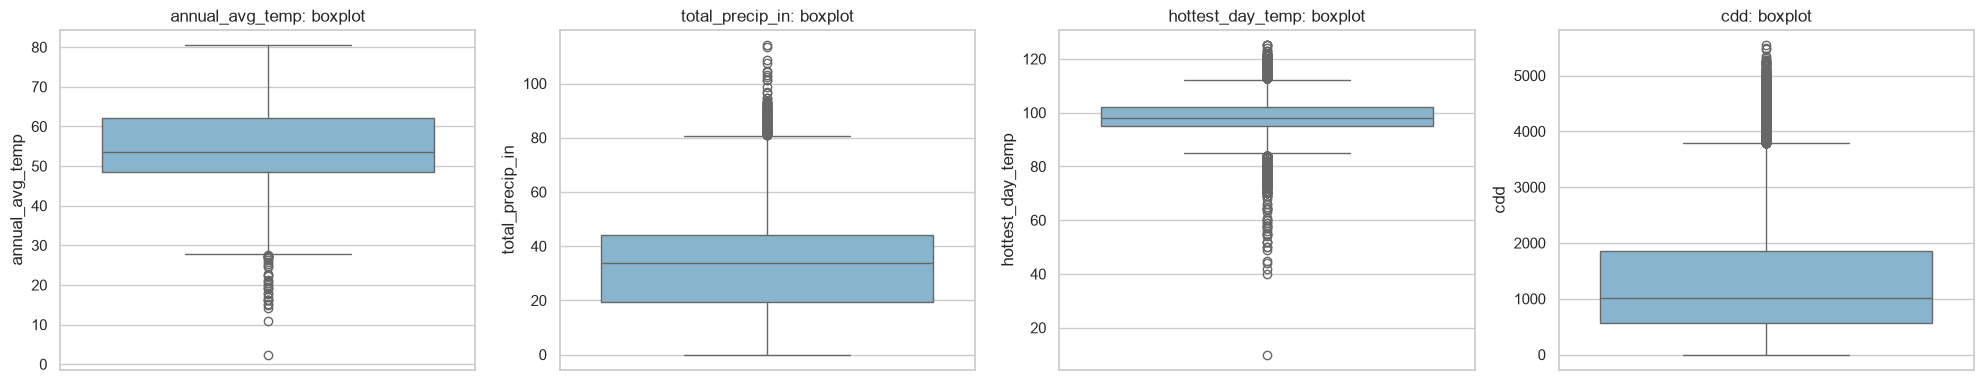

In [10]:
fig, axes = plt.subplots(1, len(CONTINUOUS_COLUMNS), figsize=(5 * len(CONTINUOUS_COLUMNS), 4))
for axis, column in zip(np.atleast_1d(axes), CONTINUOUS_COLUMNS):
    sns.boxplot(y=city_year[column], ax=axis, color="#7db7d9")
    axis.set_title(f"{column}: boxplot")
plt.tight_layout()

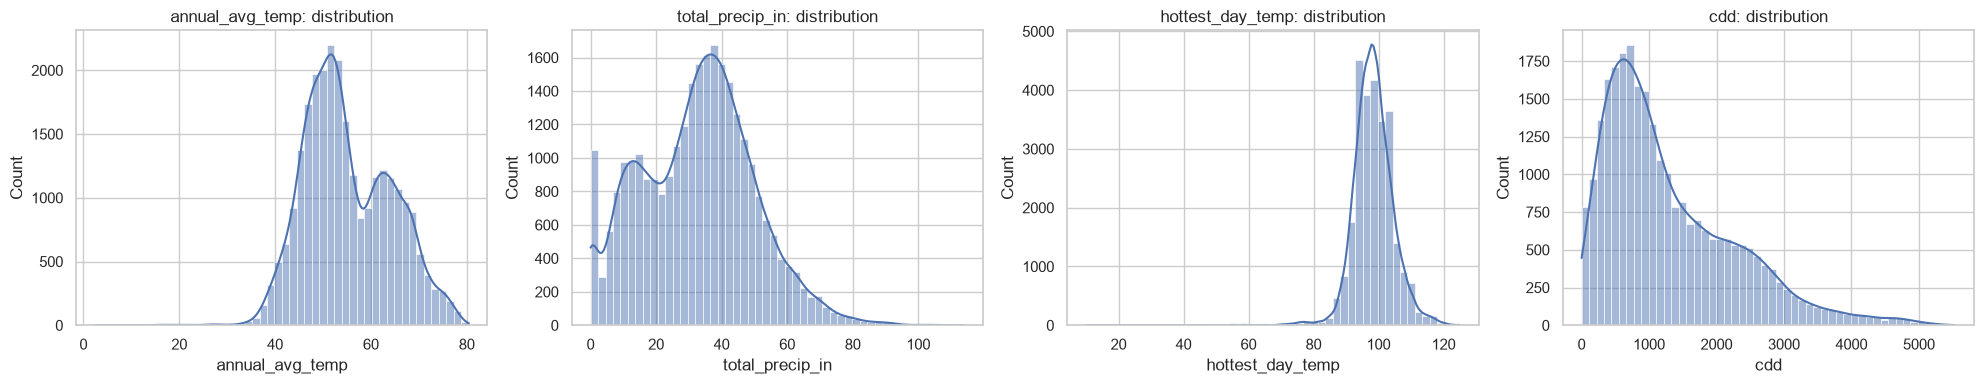

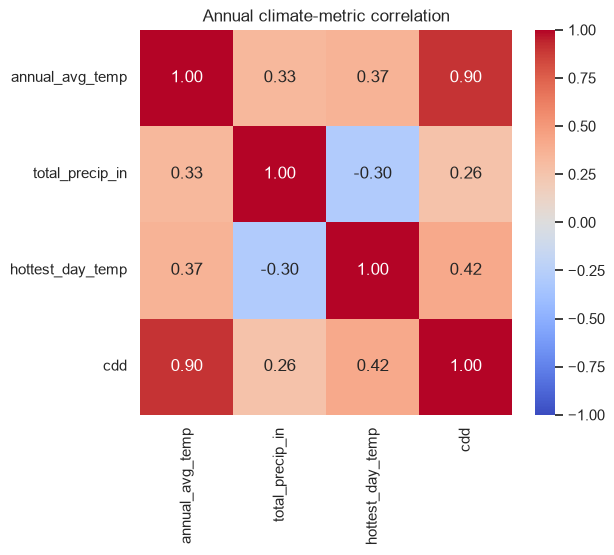

,annual_avg_temp,total_precip_in,hottest_day_temp,cdd
annual_avg_temp,1.000,0.330,0.365,0.903
total_precip_in,0.330,1.000,-0.295,0.261
hottest_day_temp,0.365,-0.295,1.000,0.417
cdd,0.903,0.261,0.417,1.000


In [11]:
fig, axes = plt.subplots(1, len(CONTINUOUS_COLUMNS), figsize=(5 * len(CONTINUOUS_COLUMNS), 4))
for axis, column in zip(np.atleast_1d(axes), CONTINUOUS_COLUMNS):
    sns.histplot(city_year[column].dropna(), bins=50, kde=True, ax=axis)
    axis.set_title(f"{column}: distribution")
plt.tight_layout()

correlation = city_year[CONTINUOUS_COLUMNS].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Annual climate-metric correlation")
plt.show()
correlation

## Quality checks

These checks expose issues; they do not silently repair them. Decide and document any treatment of invalid values or duplicate readings before proceeding.

In [12]:
quality_report = {
    "rows": len(city_year),
    "cities": city_year["city_id"].nunique(),
    "year_min": city_year["year"].min(),
    "year_max": city_year["year"].max(),
    "duplicate_city_years": int(city_year.duplicated(["city_id", "year"]).sum()),
    "negative_precip": int((city_year["total_precip_in"] < 0).sum()),
    "negative_cdd": int((city_year["cdd"] < 0).sum()),
}
pd.Series(quality_report, name="value")

rows                    28052
cities                    210
year_min                 1851
year_max                 2018
duplicate_city_years        0
negative_precip             0
negative_cdd                0
Name: value, dtype: int64

In [13]:
station_coverage = station_coverage.rename(columns={
    "ID": "city_id", "Year": "year", "Days Both": "days_both",
    "Station Segment": "station_segment", "Station Changes": "station_changes",
})
station_coverage["year"] = pd.to_numeric(station_coverage["year"], errors="coerce")
city_year = city_year.merge(
    station_coverage[["city_id", "year", "days_both", "station_segment", "station_changes"]],
    on=["city_id", "year"], how="left", validate="one_to_one"
)

# Official scoring rule: more than 10 missing relevant daily values makes that city-year metric unscored.
temperature_complete = city_year["miss_tmax"].le(10) & city_year["miss_tmin"].le(10)
city_year["valid_annual_avg_temp"] = temperature_complete
city_year["valid_hottest_day_temp"] = temperature_complete
city_year["valid_cdd"] = temperature_complete
city_year["valid_total_precip_in"] = city_year["miss_precip"].le(10)

city_year[["days_both", "station_changes", "valid_annual_avg_temp", "valid_total_precip_in"]].describe(include="all")

,days_both,station_changes,valid_annual_avg_temp,valid_total_precip_in
count,"28,052.000","28,052.000",28052,28052
unique,NaN,NaN,2,2
top,NaN,NaN,True,True
freq,NaN,NaN,24583,24858
mean,343.381,0.009,NaN,NaN
std,77.841,0.096,NaN,NaN
min,0.000,0.000,NaN,NaN
25%,364.000,0.000,NaN,NaN
50%,365.000,0.000,NaN,NaN
75%,365.000,0.000,NaN,NaN


## Finalize the city-year table

The official `annual_indices` table already contains annual aggregates, including CDD calculated from daily maximum and minimum temperatures. We retain every city-year and add metric-specific validity flags; do not drop rows merely because they are unscored. You must still predict every submission row.

In [14]:
city_year = city_year.sort_values(["city_id", "year"]).reset_index(drop=True)
city_year.head()

,city_id,city_name,latitude,longitude,year,miss_tmax,miss_tmin,miss_precip,annual_avg_temp,total_precip_in,hottest_day_temp,cdd,days_both,station_segment,station_changes,valid_annual_avg_temp,valid_hottest_day_temp,valid_cdd,valid_total_precip_in
0,USC00042863,Escondido,33.121,-117.090,1894,61,61,236,61.340,6.680,113.000,715.500,304,1,0,False,False,False,False
1,USC00042863,Escondido,33.121,-117.090,1895,4,0,319,62.340,13.550,102.000,"1,068.500",361,1,0,True,True,True,False
2,USC00042863,Escondido,33.121,-117.090,1896,0,0,323,62.620,3.640,109.000,"1,095.000",366,1,0,True,True,True,False
3,USC00042863,Escondido,33.121,-117.090,1897,0,0,236,60.090,2.320,111.000,931.000,365,1,0,True,True,True,False
4,USC00042863,Escondido,33.121,-117.090,1898,0,0,122,59.980,7.950,110.000,953.000,365,1,0,True,True,True,False


## Model-ready feature design (without leakage)

The annual outcome fields become targets. Lagged values are continuous inputs; `city_id` is nominal and must be one-hot encoded. Binary fields, if later joined from city metadata, should be integers. Ordinal fields require an explicit, documented ordering—not arbitrary labels.

The transformer below is intentionally **unfitted**. In the modelling notebook, fit it separately on each training window only, then transform that fold’s validation years.

In [15]:
TARGET_COLUMNS = [
    "annual_avg_temp",
    "total_precip_in",
    "hottest_day_temp",
    "cdd",
]

# shift(1) guarantees the feature for year t comes from no later than year t - 1.
city_year_features = city_year.copy()
for target in TARGET_COLUMNS:
    city_year_features[f"{target}_lag_1"] = (
        city_year_features.groupby("city_id")[target].shift(1)
    )

# Rows without a prior observed year cannot support lagged forecasting features.
model_table = city_year_features.dropna(
    subset=TARGET_COLUMNS + [f"{target}_lag_1" for target in TARGET_COLUMNS]
).copy()
model_table.head()

,city_id,city_name,latitude,longitude,year,miss_tmax,miss_tmin,miss_precip,annual_avg_temp,total_precip_in,hottest_day_temp,cdd,days_both,station_segment,station_changes,valid_annual_avg_temp,valid_hottest_day_temp,valid_cdd,valid_total_precip_in,annual_avg_temp_lag_1,total_precip_in_lag_1,hottest_day_temp_lag_1,cdd_lag_1
1,USC00042863,Escondido,33.121,-117.090,1895,4,0,319,62.340,13.550,102.000,"1,068.500",361,1,0,True,True,True,False,61.340,6.680,113.000,715.500
2,USC00042863,Escondido,33.121,-117.090,1896,0,0,323,62.620,3.640,109.000,"1,095.000",366,1,0,True,True,True,False,62.340,13.550,102.000,"1,068.500"
3,USC00042863,Escondido,33.121,-117.090,1897,0,0,236,60.090,2.320,111.000,931.000,365,1,0,True,True,True,False,62.620,3.640,109.000,"1,095.000"
4,USC00042863,Escondido,33.121,-117.090,1898,0,0,122,59.980,7.950,110.000,953.000,365,1,0,True,True,True,False,60.090,2.320,111.000,931.000
5,USC00042863,Escondido,33.121,-117.090,1899,2,1,0,58.490,12.090,102.000,455.000,363,1,0,True,True,True,True,59.980,7.950,110.000,953.000


In [16]:
FEATURE_COLUMNS = ["city_id", "year", "latitude", "longitude", "days_both"] + [
    f"{target}_lag_1" for target in TARGET_COLUMNS
]
CONTINUOUS_FEATURES = [column for column in FEATURE_COLUMNS if column != "city_id"]
NOMINAL_FEATURES = ["city_id"]
BINARY_FEATURES = []
ORDINAL_FEATURES = []

# If metadata adds binary variables, cast them to nullable integers before fitting.
for column in BINARY_FEATURES:
    model_table[column] = model_table[column].astype("Int64")

def make_preprocessor():
    transformers = [
        ("continuous", StandardScaler(), CONTINUOUS_FEATURES),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), NOMINAL_FEATURES),
    ]
    if ORDINAL_FEATURES:
        transformers.append(("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), ORDINAL_FEATURES))
    if BINARY_FEATURES:
        transformers.append(("binary", "passthrough", BINARY_FEATURES))
    return ColumnTransformer(transformers=transformers, remainder="drop")

X = model_table[FEATURE_COLUMNS]
y = model_table[TARGET_COLUMNS]
preprocessor = make_preprocessor()  # Do not call fit_transform(X) before a chronological split.
print(f"Unfitted feature table: {X.shape}; target table: {y.shape}")

Unfitted feature table: (26540, 9); target table: (26540, 4)


In [17]:
assert city_year.duplicated(["city_id", "year"]).sum() == 0
assert city_year["year"].max() <= 2018, "Training data must end in 2018."

output_file = DATA_PROCESSED / "city_year_climate.parquet"
city_year.to_parquet(output_file, index=False)

metadata = {
    "source_repository": REPO,
    "annual_source_rows": len(annual),
    "city_year_rows": len(city_year),
    "city_count": int(city_year["city_id"].nunique()),
    "year_range": [int(city_year["year"].min()), int(city_year["year"].max())],
    "coverage_rule": "At most 10 missing relevant daily values per city-year metric",
}
(DATA_PROCESSED / "city_year_climate_metadata.json").write_text(json.dumps(metadata, indent=2))
print(f"Saved {len(city_year):,} city-year rows to {output_file.relative_to(PROJECT_ROOT)}")
metadata

Saved 28,052 city-year rows to data\processed\city_year_climate.parquet


{'source_repository': 'CMU-OSPO/protostar-climate-train-to-2018',
 'annual_source_rows': 28052,
 'city_year_rows': 28052,
 'city_count': 210,
 'year_range': [1851, 2018],
 'coverage_rule': 'At most 10 missing relevant daily values per city-year metric'}

## Key insights

- The official source contains **28,052 city-years for 210 cities from 1851–2018**, with no duplicate city-year keys, negative precipitation, or negative CDD values.
- Coverage matters more than simple null counts. After applying the official 10-day rule, **24,583 city-years are valid for temperature/CDD metrics** and **24,858 are valid for precipitation**. An annual value can exist but still be unsuitable for official scoring because too many underlying days are missing.
- Average annual temperature and CDD are strongly related (`r = 0.903`), indicating a shared heat signal. Precipitation has much weaker relationships with the temperature targets, so it likely requires a more conservative forecasting strategy.
- Station changes are uncommon overall, but they can create artificial level shifts for affected cities and should be examined before using long trends.
- One-year lags produce a preliminary table with 26,540 rows, but feature creation and preprocessing must occur separately inside each chronological training fold to prevent leakage.

## Next notebook

Establish the starter-model benchmark using the repository's curated, cutoff-guarded data. Compare the lag-based Random Forest with the official last-year, 30-year-average, and linear-trend forecasting rules. The processed file written here is exploratory; the reproducible submission pipeline continues to use `code/prepare_data.py` and `data/annual_valid.csv`.